In [1]:
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms

# 1. Распаковка архива
with zipfile.ZipFile('dataset g.zip', 'r') as zip_ref:
  zip_ref.extractall('./')

# 2. Пайплайн аугментации
# Для деталей важно: повороты на малые углы, легкое масштабирование и подстройка яркости.
# Сильное размытие исключено, чтобы не замазать тонкие трещины.
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(degrees=15),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}

data_dir = 'dataset g'
image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'val']
}
dataloaders = {
    x: torch.utils.data.DataLoader(
        image_datasets[x], batch_size=4, shuffle=True
    )
    for x in ['train', 'val']
}

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
class_names = image_datasets['train'].classes
print(f'Используемое устройство: {device}')
print(f'Классы: {class_names}')

Используемое устройство: cuda:0
Классы: ['defect', 'good']


In [2]:
# Загрузка предобученной модели
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Заморозка весов сверточных слоев
for param in model.parameters():
  param.requires_grad = False

# Замена финального полносвязного слоя под 2 класса
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(nn.Linear(num_ftrs, 128), nn.ReLU(), nn.Linear(128, 2))

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Цикл обучения
num_epochs = 25
for epoch in range(num_epochs):
  for phase in ['train', 'val']:
    if phase == 'train':
      model.train()
    else:
      model.eval()

    running_loss = 0.0
    running_corrects = 0

    for inputs, labels in dataloaders[phase]:
      inputs = inputs.to(device)
      labels = labels.to(device)

      optimizer.zero_grad()
      with torch.set_grad_enabled(phase == 'train'):
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)

        if phase == 'train':
          loss.backward()
          optimizer.step()

      running_loss += loss.item() * inputs.size(0)
      running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len(image_datasets[phase])
    epoch_acc = running_corrects.double() / len(image_datasets[phase])

    if phase == 'val':
      print(
          f'Epoch {epoch+1}/{num_epochs} -> Loss: {epoch_loss:.4f} | Val Acc:'
          f' {epoch_acc*100:.1f}%'
      )

print('Обучение завершено!')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


Epoch 1/25 -> Loss: 0.7138 | Val Acc: 50.0%
Epoch 2/25 -> Loss: 0.7630 | Val Acc: 50.0%
Epoch 3/25 -> Loss: 0.6860 | Val Acc: 58.3%
Epoch 4/25 -> Loss: 0.6694 | Val Acc: 58.3%
Epoch 5/25 -> Loss: 0.9531 | Val Acc: 50.0%
Epoch 6/25 -> Loss: 0.6089 | Val Acc: 58.3%
Epoch 7/25 -> Loss: 0.6813 | Val Acc: 58.3%
Epoch 8/25 -> Loss: 0.7162 | Val Acc: 58.3%
Epoch 9/25 -> Loss: 0.6581 | Val Acc: 58.3%
Epoch 10/25 -> Loss: 0.6470 | Val Acc: 58.3%
Epoch 11/25 -> Loss: 0.5874 | Val Acc: 66.7%
Epoch 12/25 -> Loss: 0.6637 | Val Acc: 58.3%
Epoch 13/25 -> Loss: 0.5801 | Val Acc: 66.7%
Epoch 14/25 -> Loss: 0.6664 | Val Acc: 58.3%
Epoch 15/25 -> Loss: 0.6727 | Val Acc: 66.7%
Epoch 16/25 -> Loss: 0.5659 | Val Acc: 75.0%
Epoch 17/25 -> Loss: 0.8187 | Val Acc: 58.3%
Epoch 18/25 -> Loss: 0.7963 | Val Acc: 58.3%
Epoch 19/25 -> Loss: 0.5439 | Val Acc: 75.0%
Epoch 20/25 -> Loss: 0.7217 | Val Acc: 58.3%
Epoch 21/25 -> Loss: 0.5745 | Val Acc: 66.7%
Epoch 22/25 -> Loss: 0.6879 | Val Acc: 66.7%
Epoch 23/25 -> Loss

In [3]:
from PIL import Image

# 1. Сохранение весов для будущего использования на стенде
torch.save(model.state_dict(), 'defect_resnet18.pt')
print('Модель сохранена как defect_resnet18.pt')


# 2. Функция одиночной проверки (Inference)
def predict_image(image_path):
  model.eval()
  img = Image.open(image_path).convert('RGB')
  transform = data_transforms['val']
  tensor = transform(img).unsqueeze(0).to(device)

  with torch.no_grad():
    outputs = model(tensor)
    probs = torch.nn.functional.softmax(outputs, dim=1)
    conf, pred = torch.max(probs, 1)

  result = class_names[pred.item()]
  confidence = conf.item() * 100
  print(f'Файл: {os.path.basename(image_path)}')
  print(f'Вердикт: {result.upper()} ({confidence:.1f}% уверенность)\n')


# Пример вызова на тестовом фото:
# predict_image("dataset/val/defect/def10.jpg")

Модель сохранена как defect_resnet18.pt


In [5]:
import os

# Смотрим, какие именно файлы лежат в проверочных папках
val_defects = os.listdir('dataset g/val/defect')
val_goods = os.listdir('dataset g/val/good')

print('Файлы в val/defect:', val_defects)
print('Файлы в val/good:', val_goods)

# Автоматически проверяем первый бракованный файл из списка
if val_defects:
  file_to_test = os.path.join('dataset g/val/defect', val_defects[0])
  predict_image(file_to_test)

Файлы в val/defect: ['def3.jpg', 'def1.jpg', 'def2.jpg', 'test3.jpg', 'test4.jpg', 'def4.jpg']
Файлы в val/good: ['ref13.jpg', 'ref14.jpg', 'test7.jpg', 'ref4.jpg', 'ref15.jpg', 'test8.jpg']
Файл: def3.jpg
Вердикт: DEFECT (81.2% уверенность)



In [6]:
correct = 0
total = 0

for true_label in ['defect', 'good']:
  folder = os.path.join('dataset g/val', true_label)
  for fname in os.listdir(folder):
    path = os.path.join(folder, fname)

    # Проверка модели
    img = Image.open(path).convert('RGB')
    tensor = data_transforms['val'](img).unsqueeze(0).to(device)
    with torch.no_grad():
      pred = class_names[torch.max(model(tensor), 1)[1].item()]

    is_ok = pred == true_label
    correct += int(is_ok)
    total += 1
    mark = '✅' if is_ok else '❌'
    print(f'{mark} {fname} -> Реальный: {true_label.upper()} | Ответ: {pred.upper()}')

print(
    f'\nИтоговая точность на проверочных фото: {correct}/{total} ('
    f'{(correct/total)*100:.1f}%)'
)

✅ def3.jpg -> Реальный: DEFECT | Ответ: DEFECT
✅ def1.jpg -> Реальный: DEFECT | Ответ: DEFECT
✅ def2.jpg -> Реальный: DEFECT | Ответ: DEFECT
✅ test3.jpg -> Реальный: DEFECT | Ответ: DEFECT
✅ test4.jpg -> Реальный: DEFECT | Ответ: DEFECT
✅ def4.jpg -> Реальный: DEFECT | Ответ: DEFECT
❌ ref13.jpg -> Реальный: GOOD | Ответ: DEFECT
❌ ref14.jpg -> Реальный: GOOD | Ответ: DEFECT
❌ test7.jpg -> Реальный: GOOD | Ответ: DEFECT
✅ ref4.jpg -> Реальный: GOOD | Ответ: GOOD
❌ ref15.jpg -> Реальный: GOOD | Ответ: DEFECT
❌ test8.jpg -> Реальный: GOOD | Ответ: DEFECT

Итоговая точность на проверочных фото: 7/12 (58.3%)


In [8]:
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms

# ==========================================
# 1. РАСПАКОВКА И ПРОВЕРКА ФАЙЛОВ
# ==========================================
print('--- 1. Распаковка архива ---')
with zipfile.ZipFile('dataset g.zip', 'r') as zip_ref:
  zip_ref.extractall('./')

data_dir = 'dataset g'
for split in ['train', 'val']:
  for cls in ['good', 'defect']:
    p = os.path.join(data_dir, split, cls)
    if os.path.exists(p):
      count = len([f for f in os.listdir(p) if not f.startswith('.')])
      print(f'{split}/{cls}: {count} фото')

# ==========================================
# 2. АУГМЕНТАЦИЯ И ДАТАЛОАДЕРЫ
# ==========================================
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomRotation(degrees=15),
        transforms.RandomAffine(
            degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)
        ),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}

image_datasets = {
    x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
    for x in ['train', 'val']
}
dataloaders = {
    x: torch.utils.data.DataLoader(
        image_datasets[x], batch_size=4, shuffle=True
    )
    for x in ['train', 'val']
}

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
class_names = image_datasets['train'].classes
print(f'\nУстройство: {device} | Классы: {class_names}')

# ==========================================
# 3. НАСТРОЙКА RESNET18 С РАЗМОРОЗКОЙ LAYER4
# ==========================================
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model.parameters():
  param.requires_grad = False
for param in model.layer4.parameters():
  param.requires_grad = True

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(nn.Linear(num_ftrs, 128), nn.ReLU(), nn.Linear(128, 2))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 1e-3},
])

# ==========================================
# 4. ЦИКЛ ОБУЧЕНИЯ С АВТОСОХРАНЕНИЕМ ЛУЧШЕГО
# ==========================================
print('\n--- 2. Обучение сети ---')
best_acc = 0.0
num_epochs = 25

for epoch in range(num_epochs):
  for phase in ['train', 'val']:
    if phase == 'train':
      model.train()
    else:
      model.eval()

    running_loss, running_corrects = 0.0, 0
    for inputs, labels in dataloaders[phase]:
      inputs, labels = inputs.to(device), labels.to(device)
      optimizer.zero_grad()

      with torch.set_grad_enabled(phase == 'train'):
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        loss = criterion(outputs, labels)
        if phase == 'train':
          loss.backward()
          optimizer.step()

      running_loss += loss.item() * inputs.size(0)
      running_corrects += torch.sum(preds == labels.data)

    epoch_acc = running_corrects.double() / len(image_datasets[phase])

    if phase == 'val':
      if epoch_acc >= best_acc:
        best_acc = epoch_acc
        torch.save(model.state_dict(), 'defect_resnet18.pt')
        print(
            f'Эпоха {epoch+1:02d} | Новая лучшая точность: {best_acc*100:.1f}%'
            ' (веса сохранены)'
        )

# ==========================================
# 5. ИТОГОВАЯ ПРОВЕРКА ВСЕХ ФОТО ИЗ VAL
# ==========================================
print('\n--- 3. Проверка лучшей модели на контрольных фото ---')
model.load_state_dict(torch.load('defect_resnet18.pt'))
model.eval()

correct, total = 0, 0
for true_label in ['defect', 'good']:
  folder = os.path.join(data_dir, 'val', true_label)
  for fname in os.listdir(folder):
    if fname.startswith('.'):
      continue
    path = os.path.join(folder, fname)
    img = Image.open(path).convert('RGB')
    tensor = data_transforms['val'](img).unsqueeze(0).to(device)

    with torch.no_grad():
      outputs = model(tensor)
      probs = torch.nn.functional.softmax(outputs, dim=1)
      conf, pred_idx = torch.max(probs, 1)
      pred_label = class_names[pred_idx.item()]

    is_ok = pred_label == true_label
    correct += int(is_ok)
    total += 1
    mark = '✅' if is_ok else '❌'
    print(
        f'{mark} {fname} -> Истинный: {true_label.upper()} | Ответ:'
        f' {pred_label.upper()} ({conf.item()*100:.1f}%)'
    )

print(f'\nИтоговый результат: {correct}/{total} ({(correct/total)*100:.1f}%)')

--- 1. Распаковка архива ---
train/good: 13 фото
train/defect: 15 фото
val/good: 6 фото
val/defect: 6 фото

Устройство: cuda:0 | Классы: ['defect', 'good']

--- 2. Обучение сети ---
Эпоха 01 | Новая лучшая точность: 50.0% (веса сохранены)
Эпоха 02 | Новая лучшая точность: 58.3% (веса сохранены)
Эпоха 03 | Новая лучшая точность: 66.7% (веса сохранены)
Эпоха 05 | Новая лучшая точность: 75.0% (веса сохранены)
Эпоха 06 | Новая лучшая точность: 91.7% (веса сохранены)
Эпоха 07 | Новая лучшая точность: 91.7% (веса сохранены)
Эпоха 12 | Новая лучшая точность: 91.7% (веса сохранены)
Эпоха 18 | Новая лучшая точность: 91.7% (веса сохранены)
Эпоха 19 | Новая лучшая точность: 100.0% (веса сохранены)
Эпоха 21 | Новая лучшая точность: 100.0% (веса сохранены)
Эпоха 22 | Новая лучшая точность: 100.0% (веса сохранены)
Эпоха 24 | Новая лучшая точность: 100.0% (веса сохранены)
Эпоха 25 | Новая лучшая точность: 100.0% (веса сохранены)

--- 3. Проверка лучшей модели на контрольных фото ---
✅ def3.jpg -> Ист

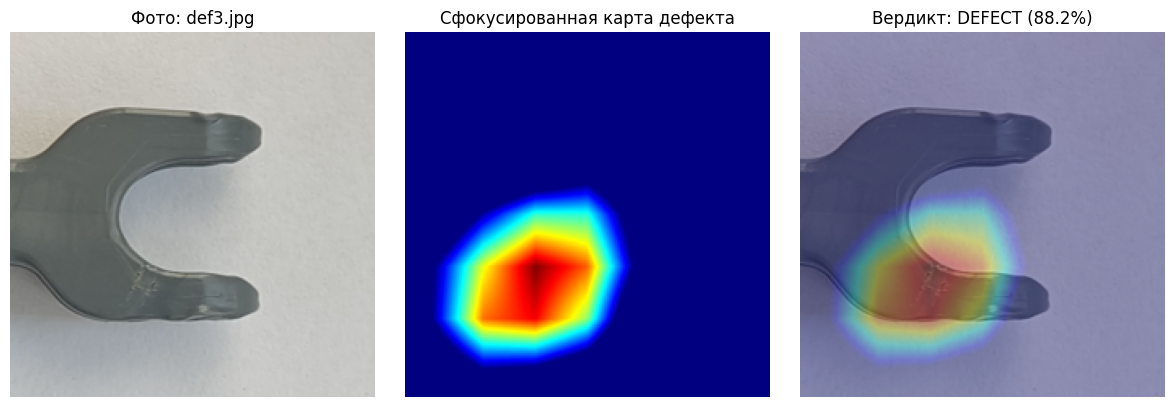

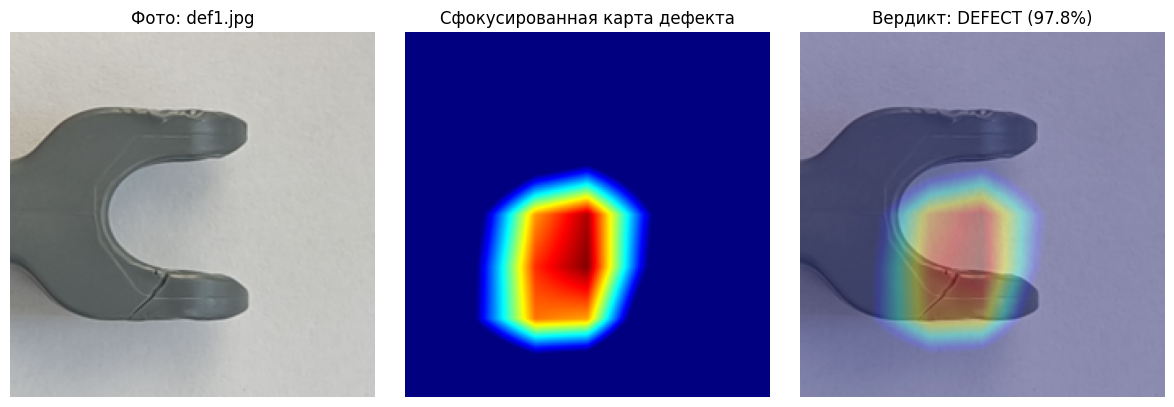

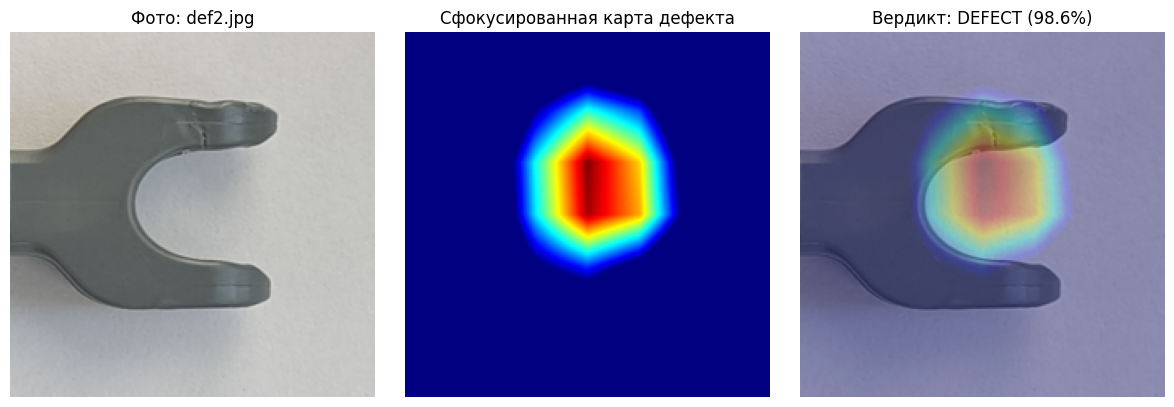

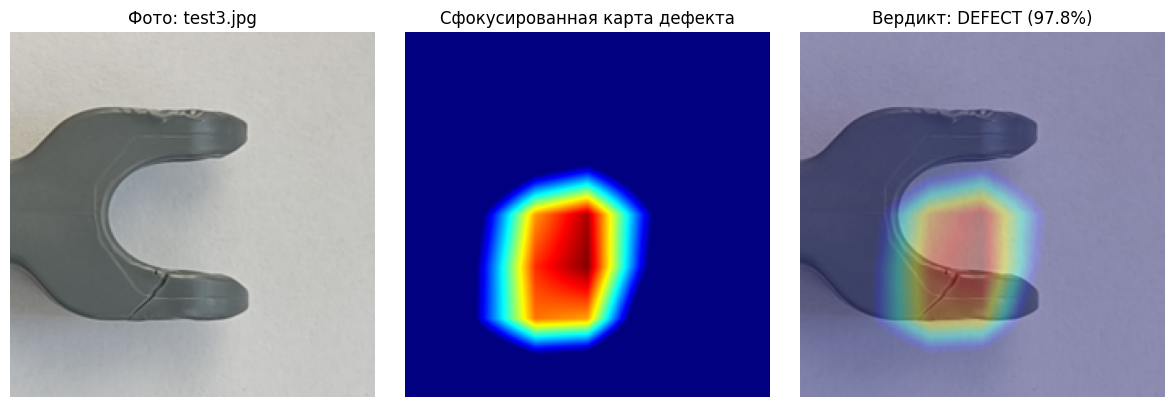

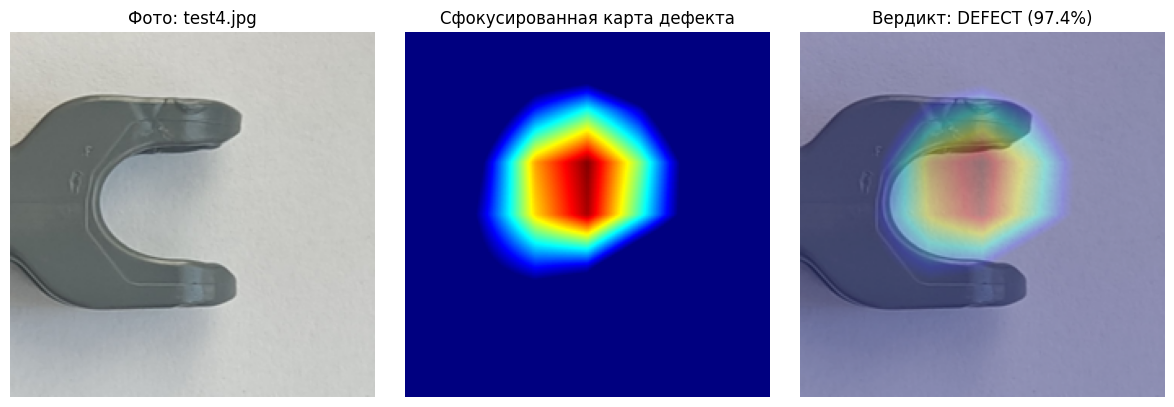

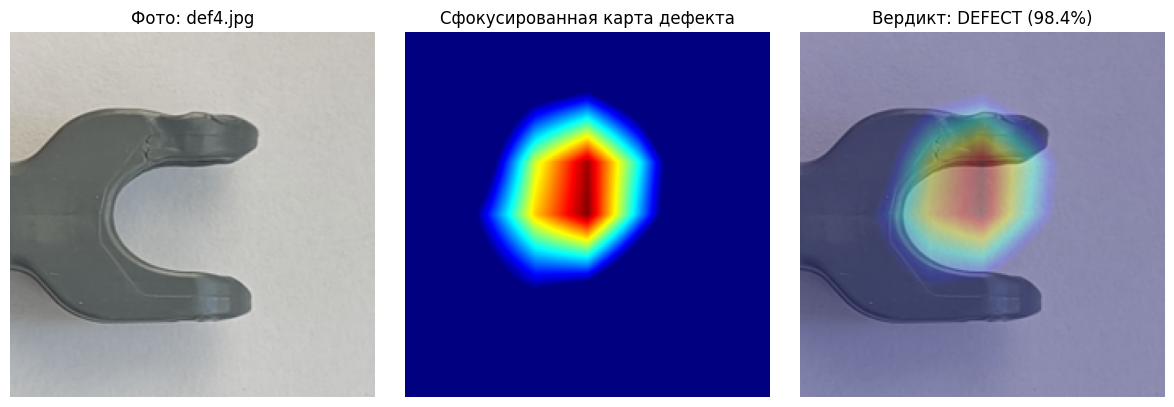

In [15]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

# ==========================================
# 1. ЧИСТАЯ ЗАГРУЗКА МОДЕЛИ ИЗ ВАШЕГО ФАЙЛА
# ==========================================
# Создаем чистую модель с нуля, чтобы стереть все зависшие хуки
model = models.resnet18(weights=None)
num_ftrs = model.fc.in_features
model.fc = nn.Sequential(nn.Linear(num_ftrs, 128), nn.ReLU(), nn.Linear(128, 2))

# Загружаем ваши обученные веса 100% точности
model.load_state_dict(torch.load('defect_resnet18.pt'))
model = model.to(device)
model.eval()

# Включаем градиенты для извлечения карты признаков
for param in model.parameters():
  param.requires_grad = True


# ==========================================
# 2. БЕЗОПАСНЫЙ GRAD-CAM ДЛЯ LAYER4
# ==========================================
class CleanGradCAM:

  def __init__(self, model, target_layer):
    self.model = model
    self.target_layer = target_layer
    self.activations = None
    self.gradients = None

    self.hook_f = self.target_layer.register_forward_hook(self.forward_hook)
    self.hook_b = self.target_layer.register_full_backward_hook(
        self.backward_hook
    )

  def forward_hook(self, module, inp, out):
    self.activations = out.detach()

  def backward_hook(self, module, grad_in, grad_out):
    self.gradients = grad_out[0].detach()

  def generate(self, input_tensor, class_idx):
    self.model.zero_grad()
    output = self.model(input_tensor)
    loss = output[0, class_idx]
    loss.backward()

    weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
    cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
    cam = F.relu(cam)
    cam = cam - cam.min()
    if cam.max() > 0:
      cam = cam / cam.max()
    return cam.cpu().numpy()


# Подключаем к последнему блоку
cam_gen = CleanGradCAM(model, model.layer4[-1])


# ==========================================
# 3. ФОКУСИРОВКА НА ДЕФЕКТЕ (КОНТРАСТНАЯ КАРТА)
# ==========================================
def show_focused_heatmap(image_path):
  orig_img = Image.open(image_path).convert('RGB')
  orig_resized = orig_img.resize((224, 224))
  input_tensor = data_transforms['val'](orig_img).unsqueeze(0).to(device)

  # Предсказание
  output = model(input_tensor)
  probs = F.softmax(output, dim=1)
  conf, pred_idx = torch.max(probs, 1)

  pred_label = class_names[pred_idx.item()]
  confidence = conf.item() * 100

  # Генерация тепловой карты
  mask = cam_gen.generate(input_tensor, pred_idx.item())
  mask_resized = cv2.resize(mask, (224, 224))

  # Срезаем размытый фон: оставляем только верхние 40% самых сильных сигналов,
  # чтобы пятно не расползалось на всю вилку, а концентрировалось на изломе
  threshold = 0.5
  focused_mask = np.where(
      mask_resized > threshold, (mask_resized - threshold) / (1 - threshold), 0
  )

  heatmap = cv2.applyColorMap(np.uint8(255 * focused_mask), cv2.COLORMAP_JET)
  heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

  img_np = np.array(orig_resized)
  overlay = np.uint8(0.7 * img_np + 0.3 * heatmap)

  fig, axes = plt.subplots(1, 3, figsize=(12, 4))
  axes[0].imshow(orig_resized)
  axes[0].set_title(f'Фото: {os.path.basename(image_path)}')
  axes[0].axis('off')

  axes[1].imshow(heatmap)
  axes[1].set_title('Сфокусированная карта дефекта')
  axes[1].axis('off')

  axes[2].imshow(overlay)
  axes[2].set_title(f'Вердикт: {pred_label.upper()} ({confidence:.1f}%)')
  axes[2].axis('off')

  plt.tight_layout()
  plt.show()


# Проверяем все бракованные фото
for f in os.listdir('dataset g/val/defect'):
  if not f.startswith('.'):
    show_focused_heatmap(os.path.join('dataset g/val/defect', f))

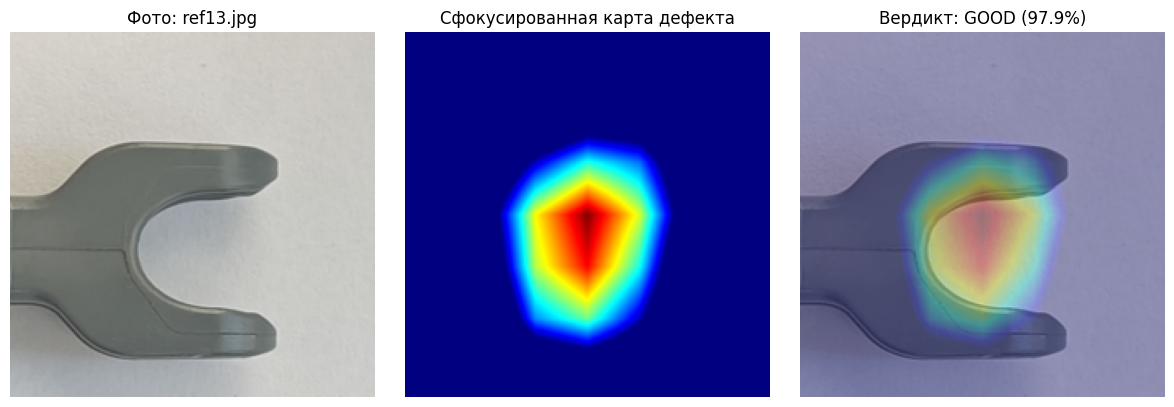

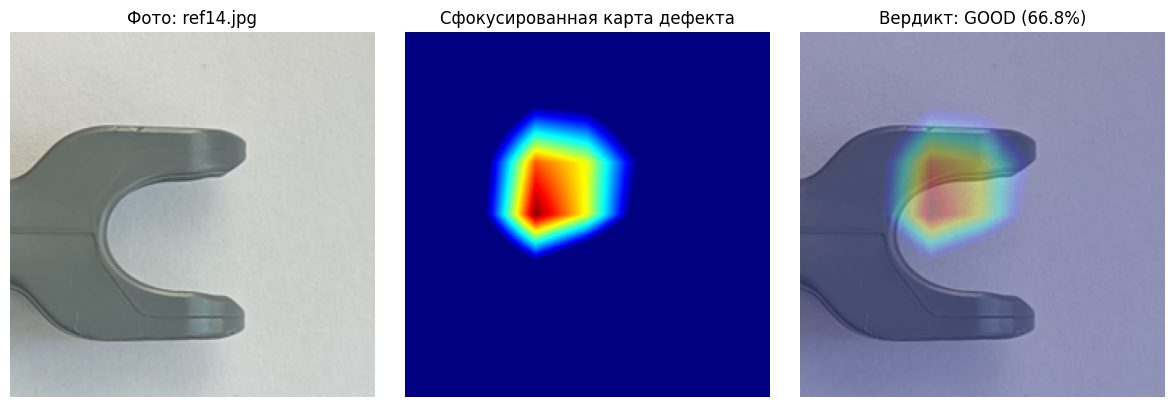

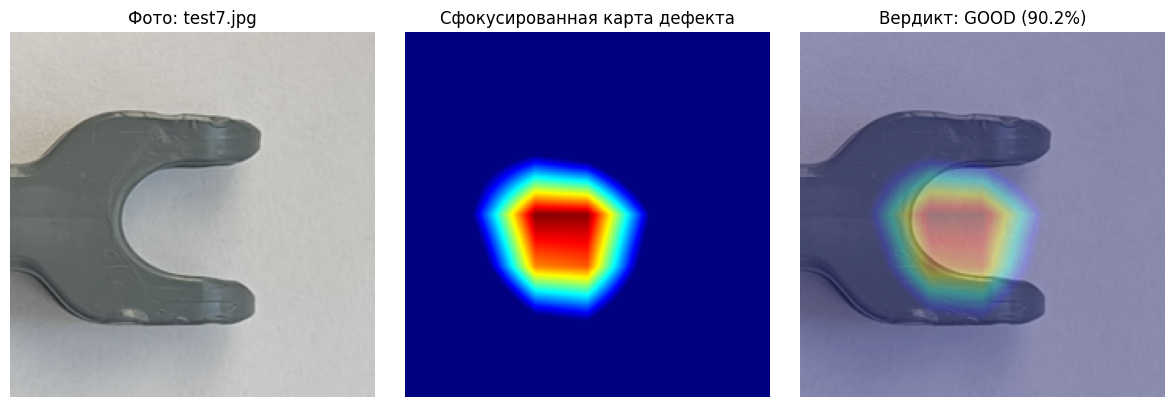

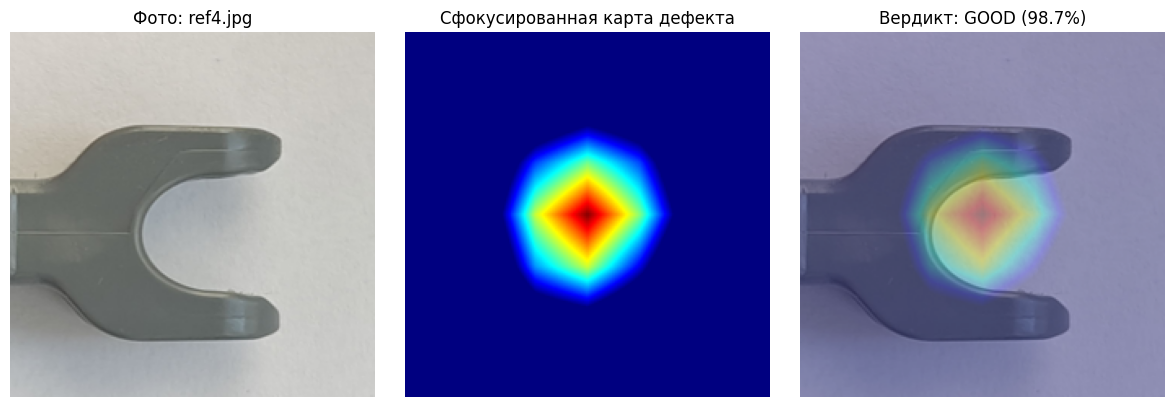

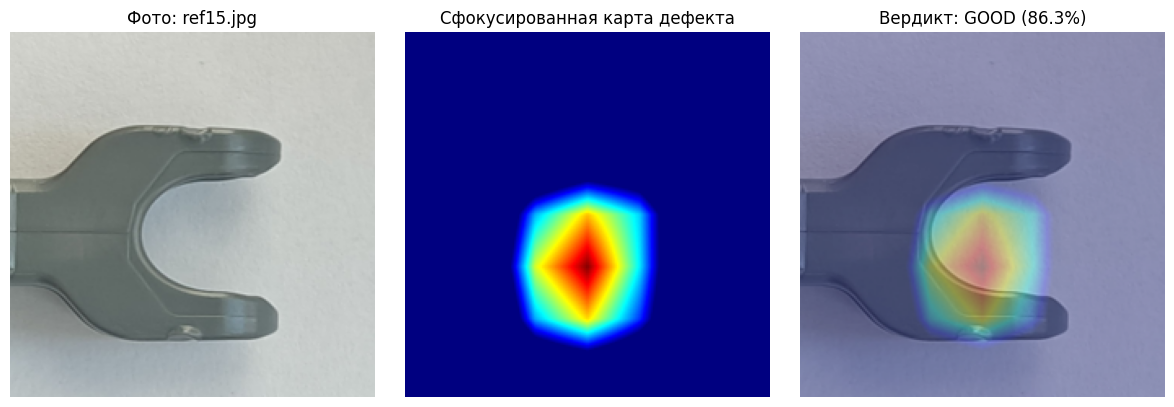

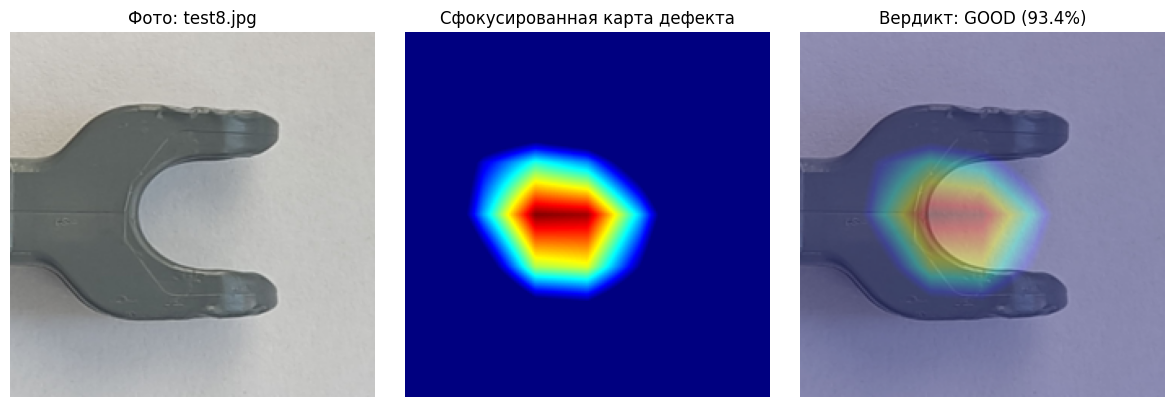

In [16]:
# Запуск тепловой карты для эталонных (годных) деталей
for f in os.listdir('dataset g/val/good'):
  if not f.startswith('.'):
    show_focused_heatmap(os.path.join('dataset g/val/good', f))

In [18]:
# 1. Установка недостающего модуля (займет 5 секунд)
!pip install onnx onnxscript

# 2. Экспорт модели
dummy_input = torch.randn(1, 3, 224, 224, device=device)
torch.onnx.export(
    model,
    dummy_input,
    'defect_resnet18.onnx',
    input_names=['input'],
    output_names=['output'],
    opset_version=12,
)
print('Файл defect_resnet18.onnx успешно создан!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 58.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 21.6 MB/s eta 0:00:00


W1012 11:17:58.894000 494 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version

[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Файл defect_resnet18.onnx успешно создан!
